In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines, plot_hist, plot_line_diff, make_figure, set_ticks
from crafts_stack.halo_fitting import halofit, cov_to_err_map
from crafts_stack.halo_models import build_model, apply_prior
from astropy.stats import sigma_clip

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

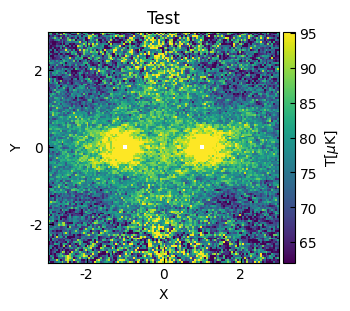

In [3]:
# data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
# data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

data = sigma_clip(data, sigma=10, masked=True)
plot_heatmap(data, title='Test')

In [4]:
model = build_model('nfw') + build_model('lorentz', 'const')
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Lorentz2D(amplitude=50., x_mean=-1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>

    [3]: <Lorentz2D(amplitude=50., x_mean=1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>

    [4]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... fwhm_3 ellipticity_3 theta_3 amplitude_4
    ----------- -------- -------- ----- ... ------ ------------- ------- -----------
           50.0     -1.0      0.0   0.5 ...    1.0           0.0     0.0         0.0


In [5]:
model.param_names

('amplitude_0',
 'x_mean_0',
 'y_mean_0',
 'r_s_0',
 'ellipticity_0',
 'theta_0',
 'amplitude_1',
 'x_mean_1',
 'y_mean_1',
 'r_s_1',
 'ellipticity_1',
 'theta_1',
 'amplitude_2',
 'x_mean_2',
 'y_mean_2',
 'fwhm_2',
 'ellipticity_2',
 'theta_2',
 'amplitude_3',
 'x_mean_3',
 'y_mean_3',
 'fwhm_3',
 'ellipticity_3',
 'theta_3',
 'amplitude_4')

In [6]:
coord = get_coord()


tolenrance = 0.1

bounds = {
    # 'amplitude_0': (0, 200),
    # 'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    # 'ellipticity_0': (0, 0.5),
    # 'ellipticity_1': (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1','x_mean_2', 'y_mean_2', 'x_mean_3', 'y_mean_3'], # fix the center of the two NFW profiles
    "tied": [
        # ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        # ("ellipticity_1", "ellipticity_0"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}

model = apply_prior(model, bounds=bounds, constraints=constraints)
print(model.tied)
print(model.fixed)

{'amplitude_0': False, 'x_mean_0': False, 'y_mean_0': False, 'r_s_0': False, 'ellipticity_0': False, 'theta_0': False, 'amplitude_1': False, 'x_mean_1': False, 'y_mean_1': False, 'r_s_1': False, 'ellipticity_1': False, 'theta_1': False, 'amplitude_2': False, 'x_mean_2': False, 'y_mean_2': False, 'fwhm_2': False, 'ellipticity_2': False, 'theta_2': False, 'amplitude_3': False, 'x_mean_3': False, 'y_mean_3': False, 'fwhm_3': False, 'ellipticity_3': False, 'theta_3': False, 'amplitude_4': False}
{'amplitude_0': False, 'x_mean_0': True, 'y_mean_0': True, 'r_s_0': False, 'ellipticity_0': False, 'theta_0': False, 'amplitude_1': False, 'x_mean_1': True, 'y_mean_1': True, 'r_s_1': False, 'ellipticity_1': False, 'theta_1': False, 'amplitude_2': False, 'x_mean_2': True, 'y_mean_2': True, 'fwhm_2': False, 'ellipticity_2': False, 'theta_2': False, 'amplitude_3': False, 'x_mean_3': True, 'y_mean_3': True, 'fwhm_3': False, 'ellipticity_3': False, 'theta_3': False, 'amplitude_4': False}


# without mask

In [7]:
data_list, fit_model, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=48.61626679, x_mean=-1., y_mean=0., r_s=0.18690289, ellipticity=0., theta=-21.72728653)>

    [1]: <NFW2D(amplitude=48.61969297, x_mean=1., y_mean=0., r_s=0.18974776, ellipticity=0., theta=-10.04871941)>

    [2]: <Lorentz2D(amplitude=43.73519489, x_mean=-1., y_mean=0., fwhm=10.55635712, ellipticity=0., theta=135.23664188)>

    [3]: <Lorentz2D(amplitude=43.44752984, x_mean=1., y_mean=0., fwhm=10.7533106, ellipticity=0., theta=-119.61497625)>

    [4]: <Const2D(amplitude=6.54003758)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...       theta_3          amplitude_4   
    ----------------- -------- -------- ... ------------------- -----------------
    48.61626679098674     -1.0      0.0 ... -119.61497625203134 6.540037581812297

Goodness of fit:
Chi-squared: 1157828.496
Reduced chi-squared: 80.545
RMS

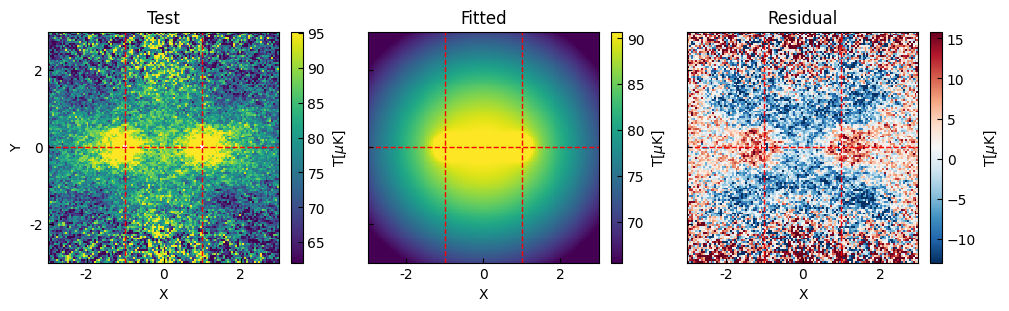

In [8]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
# axes =  plot_stack_fit_res(data_list, title=title, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

/home/dyliu/code/crafts_stack/src/crafts_stack/halo_fitting.py:212: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  free_param_samples = rng.multivariate_normal(p_free_best, cov, size=n_samples)


<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

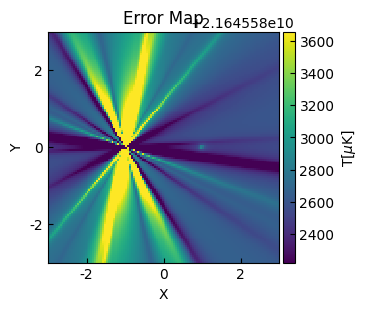

In [9]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

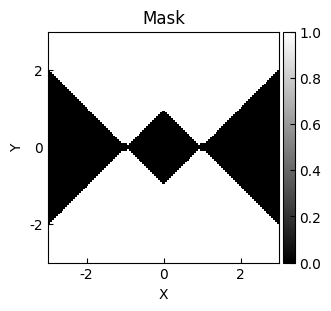

In [10]:
# mask_sector = get_mask_sector(coord=coord)
mask_sector = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask_sector = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask_sector, title='Mask', cmap='gray', cbar_label='')

In [11]:
data_list_sector, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sector, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=0.15039105, x_mean=-1., y_mean=0., r_s=44.12452025, ellipticity=0.38459847, theta=-1.55009927)>

    [1]: <NFW2D(amplitude=4.39335004, x_mean=1., y_mean=0., r_s=1.5525387, ellipticity=0.11906463, theta=1.48018626)>

    [2]: <Lorentz2D(amplitude=41.49738675, x_mean=-1., y_mean=0., fwhm=18.83008045, ellipticity=0., theta=0.04954127)>

    [3]: <Lorentz2D(amplitude=13.13942889, x_mean=1., y_mean=0., fwhm=71.70911414, ellipticity=0.89994701, theta=4.66727115)>

    [4]: <Const2D(amplitude=24.53897683)>
Parameters:
        amplitude_0     x_mean_0 y_mean_0 ...      theta_3          amplitude_4   
    ------------------- -------- -------- ... ------------------ -----------------
    0.15039105186994425     -1.0      0.0 ... 4.6672711532724085 24.53897682631845

Goodness of fit:
Chi-squared: 818049.520
Reduced chi-s

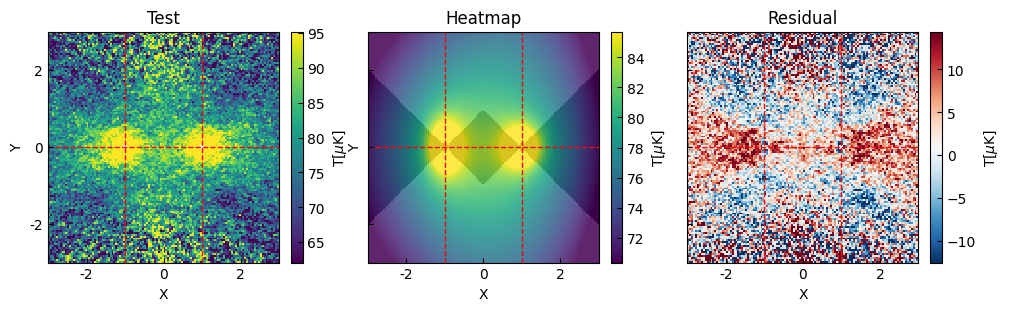

In [12]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask_sector)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

/home/dyliu/code/crafts_stack/src/crafts_stack/halo_fitting.py:212: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  free_param_samples = rng.multivariate_normal(p_free_best, cov, size=n_samples)


<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

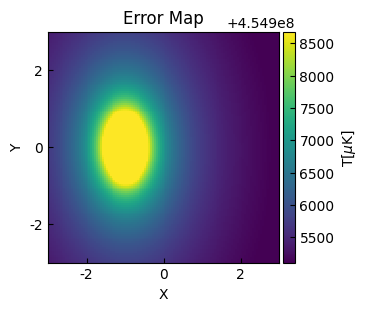

In [13]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

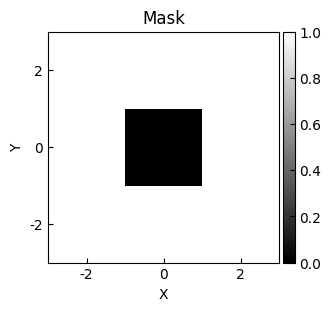

In [14]:
# mask_sq = ~get_mask_square(coord=coord)
mask_sq = ~get_mask_square(coord=coord, xlim=[-1, 1], ylim=[-1, 1])

plot_heatmap(mask_sq, title='Mask', cmap='gray', cbar_label='')

In [15]:
data_list_square, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sq, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=48.02541881, x_mean=-1., y_mean=0., r_s=0.25264496, ellipticity=0., theta=9.80626164)>

    [1]: <NFW2D(amplitude=48.03560348, x_mean=1., y_mean=0., r_s=0.25354926, ellipticity=0., theta=6.79834359)>

    [2]: <Lorentz2D(amplitude=40.91302799, x_mean=-1., y_mean=0., fwhm=13.18554679, ellipticity=0., theta=-1.94402571)>

    [3]: <Lorentz2D(amplitude=39.97749695, x_mean=1., y_mean=0., fwhm=13.32866045, ellipticity=0., theta=-31.30187679)>

    [4]: <Const2D(amplitude=7.18274297)>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...       theta_3         amplitude_4   
    ------------------ -------- -------- ... ------------------- ----------------
    48.025418808761295     -1.0      0.0 ... -31.301876789654077 7.18274297285995

Goodness of fit:
Chi-squared: 978835.593
Reduced chi-squared: 76.621
RMS resid

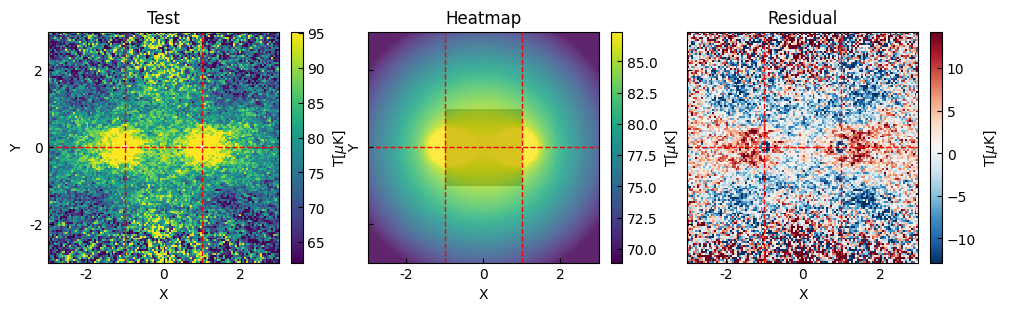

In [16]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq)
# axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

/home/dyliu/code/crafts_stack/src/crafts_stack/halo_fitting.py:212: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  free_param_samples = rng.multivariate_normal(p_free_best, cov, size=n_samples)


<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

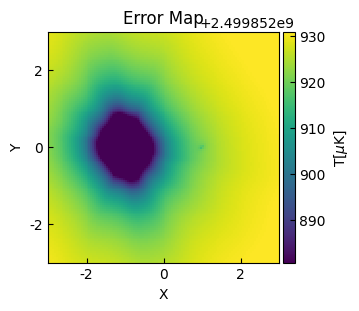

In [17]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# compare

(-100.0, 100.0)

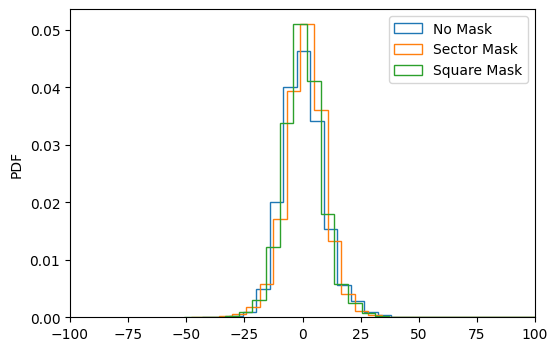

In [18]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
# title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100)
ax.set_xlim(-100, 100)

# profiles

In [19]:
# stack_fit_res = data_list
# stack_fit_res = data_list_sector
stack_fit_res = data_list_square

In [20]:
get_yprofile = lambda dlist, ind: [x[ind,:] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:,ind] for x in dlist]

lines_list = [
    get_yprofile(stack_fit_res[:2], 60),
    get_xprofile(stack_fit_res[:2], 40),
    get_xprofile(stack_fit_res[:2], 80),
]
title_list = ['Y=0', 'X=-1', 'X=1']

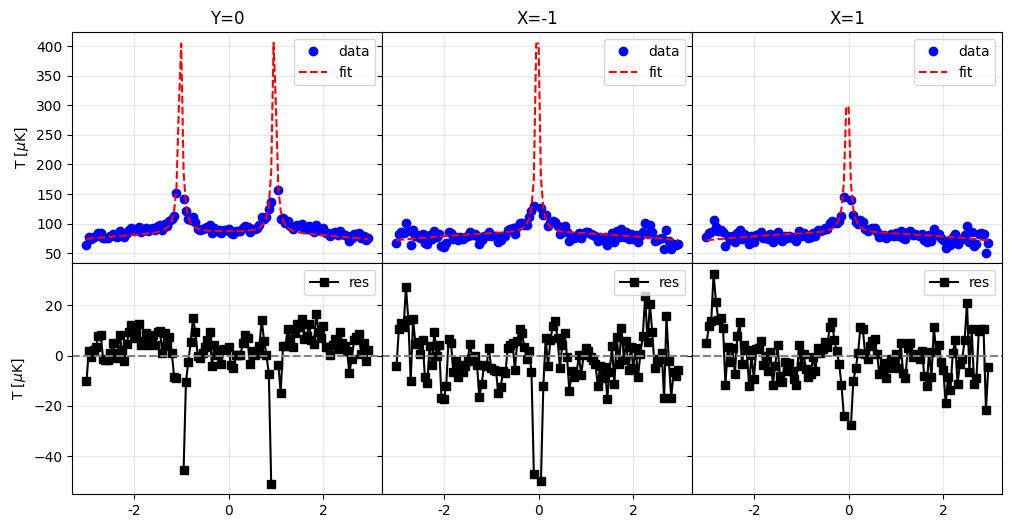

In [21]:
fig, axes = make_figure(2,3, figsize=(12,6), wspace=0., hspace=0.,aspect=None,sharex=True, sharey='row')

for i, lines in enumerate(lines_list):
    _axes = [axes[0,i], axes[1,i]]

    plot_line_diff(*lines, title=title_list[i], axes=_axes, labels=['data', 'fit', 'res'])

axes[0,0].set_ylabel(r'T [$\mu$K]')
axes[1,0].set_ylabel(r'T [$\mu$K]')
set_ticks(axes[1,0], share=False)

# estimate signal level

In [22]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure
from mytools.data import read_h5

<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

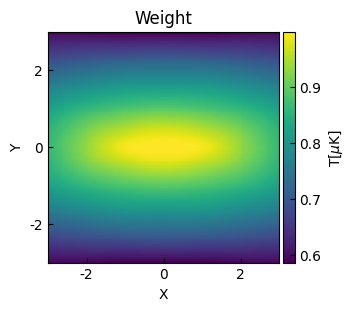

In [23]:
weight_path= '../data/pixcount_xsize3000_nfs10.h5'
pix_weights = read_h5(weight_path, 'tng_120k/weight')
# weights = read_h5(weight_path, 'crafts_122k/weight')
plot_heatmap(pix_weights, title='Weight', q=0.1)

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(0.5046317846588574), np.float64(0.0), np.float64(0.2), np.float64(0.2688148605902665)]
Gauss fit covariance: 
[[ 0.22306292 -0.05090004 -0.01169634]
 [-0.05090004  0.05090748 -0.00897683]
 [-0.01169634 -0.00897683  0.01627982]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 2142.041
Reduced chi-squared: 18.308
RMS residual: 4.225

width: 0.2
width_pix: 4


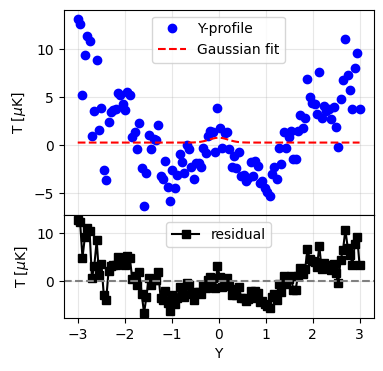

In [30]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.2, 0.7),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(res, weights=pix_weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True);
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

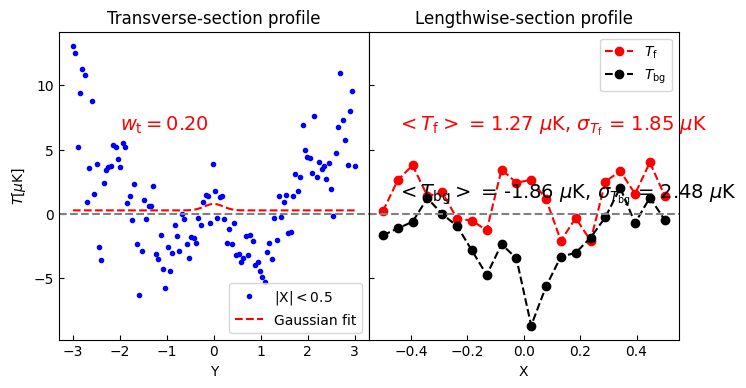

In [31]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

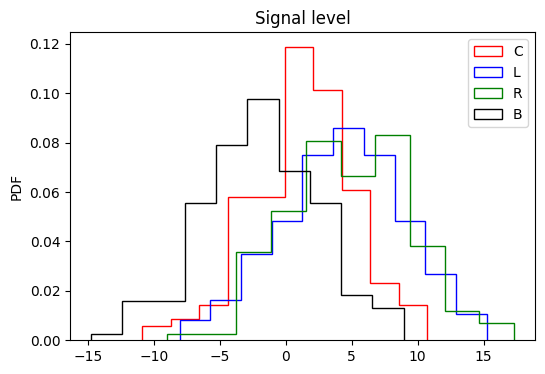

In [32]:
plot_hist(clrb, label=['C','L','R','B'], color=['r', 'b','g','k'], title='Signal level')